# 12 — Validate the binary regional neural network

## Objective

Evaluate the saved regional neural network on the existing validation images. Predict each patch from RGB features, count defective patches per image, and apply the threshold saved by Notebook 11 to produce image-level PASS/FAIL classifications.

## Load the saved model and decision settings

Read the trained pipeline and saved JSON configuration. Reuse the saved patch size and allowable defective-patch count without tuning them on validation images.

In [10]:
# Standard library imports
from pathlib import Path
import json
import time

# Numerical and tabular processing
import numpy as np
import pandas as pd

# Image processing and plotting
from PIL import Image
import matplotlib.pyplot as plt

# Load saved machine learning model
import joblib

# Classification performance metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Validation image and annotation locations
VALID_DIR = Path("../data/cleaned/valid")
COCO_PATH = VALID_DIR / "_annotations.coco.json"

# Files saved by Notebook 11
MODEL_PATH = Path("../models/binary_region_nn.joblib")
THRESHOLD_PATH = Path("../models/binary_region_nn_threshold.json")

# Load the neural network, including its fitted scaler.
nn_pipeline = joblib.load(MODEL_PATH)

# Load the failure criterion selected on training images.
with open(THRESHOLD_PATH, "r") as f:
    threshold_config = json.load(f)

MAX_DEFECTS = int(threshold_config["max_defects"])
PATCH_SIZE = int(threshold_config["patch_size"])

# Preserve the training feature order.
FEATURE_COLS = [
    "mean_r", "mean_g", "mean_b",
    "std_r", "std_g", "std_b"
]

print("Neural network loaded successfully.")
print(f"Patch size: {PATCH_SIZE} x {PATCH_SIZE}")
print(f"Maximum allowable defective regions: {MAX_DEFECTS}")


Neural network loaded successfully.
Patch size: 32 x 32
Maximum allowable defective regions: 12


## Construct validation reference labels

Read the validation COCO records and assign FAIL to images with at least one annotation, otherwise PASS.

In [11]:
# Load COCO annotation data for the validation images.
with open(COCO_PATH, "r") as f:
    valid_coco = json.load(f)

# Extract image records and defect annotations.
valid_images = valid_coco["images"]
valid_annotations = valid_coco["annotations"]

# Identify validation images containing at least one annotation.
annotated_image_ids = {
    annotation["image_id"]
    for annotation in valid_annotations
}

print(f"Validation images: {len(valid_images)}")
print(f"Validation annotations: {len(valid_annotations)}")

# Ground truth:
# 0 = PASS, no defect annotations
# 1 = FAIL, one or more defect annotations
actual_labels = [
    int(image["id"] in annotated_image_ids)
    for image in valid_images
]

print(f"Actual PASS images: {actual_labels.count(0)}")
print(f"Actual FAIL images: {actual_labels.count(1)}")


Validation images: 120
Validation annotations: 121
Actual PASS images: 14
Actual FAIL images: 106


## Define patch extraction

Divide RGB images into non-overlapping patches and retain partial patches along image boundaries.

In [12]:
# Make the project package importable when running from notebooks/.
import sys
from pathlib import Path

_SRC_PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src" / "__init__.py").is_file()
)
if str(_SRC_PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(_SRC_PROJECT_ROOT))

from src.patch_processing import extract_patches


## Define RGB feature extraction

Compute the six patch-level colour statistics in the same feature order used during training.

In [13]:
from src.feature_extraction import extract_region_rgb_features as extract_rgb_features


## Predict image-level outcomes

Predict each image’s patches and count defects. Classify the image as FAIL only when the count exceeds the saved threshold, and record processing time.

In [14]:

# Store one result per validation image.
validation_records = []

# Record processing time.
start_time = time.time()

for image_info in valid_images:

    image_id = image_info["id"]
    filename = image_info["file_name"]

    # Load the original validation image as RGB.
    image_path = VALID_DIR / filename

    with Image.open(image_path) as img:
        image = img.convert("RGB")

        # Divide the image into 32x32 regions.
        patches = extract_patches(
            image,
            patch_size=PATCH_SIZE
        )

    # Extract the same six RGB features used during training.
    patch_features = pd.DataFrame([
        extract_rgb_features(patch["rgb"])
        for patch in patches
    ])[FEATURE_COLS]

    # Generate strict binary classifications.
    # 0 = NON-DEFECT, 1 = DEFECT.
    region_predictions = nn_pipeline.predict(patch_features)

    # Count the regions classified as defective.
    defective_count = int(np.sum(region_predictions))

    # Apply the image-level failure criterion from Notebook 11.
    # More than MAX_DEFECTS regions means FAIL.
    predicted_label = int(defective_count > MAX_DEFECTS)

    # Determine the actual classification using COCO annotations.
    actual_label = int(image_id in annotated_image_ids)

    validation_records.append({
        "image_id": image_id,
        "filename": filename,
        "total_regions": len(patches),
        "predicted_defect_count": defective_count,
        "predicted_label": predicted_label,
        "actual_label": actual_label
    })

# Convert results into an image-level DataFrame.
validation_df = pd.DataFrame(validation_records)

# Calculate processing time.
processing_time = time.time() - start_time

print(f"Images processed: {len(validation_df)}")
print(f"Processing time: {processing_time:.2f} seconds")

# Verify that every validation image was processed exactly once.
assert len(validation_df) == len(valid_images)
assert validation_df["image_id"].is_unique

display(validation_df.head(10))


Images processed: 120
Processing time: 4.74 seconds


,image_id,filename,total_regions,predicted_defect_count,predicted_label,actual_label
0,0,frame_with_red_8649_jpg.rf.a4d923187143603a280...,391,15,1,1
1,1,frame_with_red_2115_jpg.rf.2eb3c4cff72bd0c8282...,391,11,0,0
2,2,frame_with_red_8627_jpg.rf.e0f16b203d1ac259b6c...,391,8,0,1
3,3,frame_with_red_2289_jpg.rf.e4cabf0fac8d843cef9...,391,22,1,1
4,4,frame_with_red_8526_jpg.rf.8a95c208e25b872ba67...,391,25,1,1
5,5,frame_with_red_531_jpg.rf.d1bf4eab747883d5e9fa...,391,40,1,1
6,6,frame_with_red_1308_jpg.rf.4fe453ba69054077d74...,391,6,0,0
7,7,frame_with_red_6194_jpg.rf.6c5b8fe814fbf13689b...,391,13,1,1
8,8,frame_with_red_9311_jpg.rf.42e8694a15dd5e3b34e...,391,7,0,1
9,9,frame_with_red_2617_jpg.rf.a1009fb1133a89370a9...,391,27,1,1


## Report classification metrics

Compare image-level predictions against reference labels using accuracy, balanced accuracy, macro F1 and the classification report.

In [15]:

# Extract actual and predicted image-level labels.
y_true = validation_df["actual_label"]
y_pred = validation_df["predicted_label"]

# Calculate classification metrics.
validation_accuracy = accuracy_score(y_true, y_pred)

validation_balanced_accuracy = balanced_accuracy_score(
    y_true, y_pred
)

validation_macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print(f"Validation accuracy: {validation_accuracy:.2%}")
print(
    f"Validation balanced accuracy: "
    f"{validation_balanced_accuracy:.2%}"
)
print(f"Validation macro F1: {validation_macro_f1:.3f}")

# Display class-specific precision, recall and F1 scores.
print("\nImage-level classification report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["PASS", "FAIL"],
        digits=3,
        zero_division=0
    )
)


Validation accuracy: 71.67%
Validation balanced accuracy: 77.76%
Validation macro F1: 0.613

Image-level classification report:
              precision    recall  f1-score   support

        PASS      0.273     0.857     0.414        14
        FAIL      0.974     0.698     0.813       106

    accuracy                          0.717       120
   macro avg      0.623     0.778     0.613       120
weighted avg      0.892     0.717     0.767       120



## Inspect the confusion matrix

Rows are actual classes and columns are predicted classes, ordered PASS then FAIL. Actual FAIL predicted PASS is a missed labelled defect.

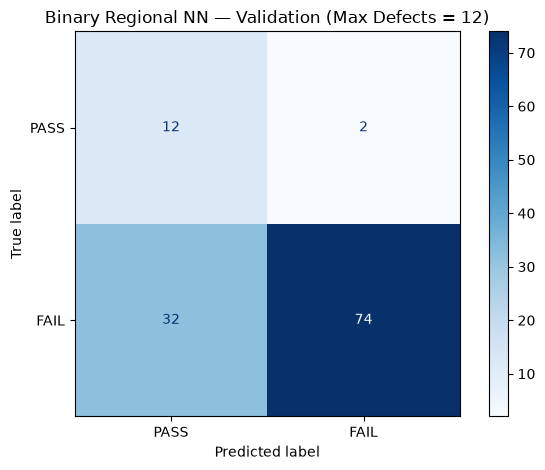

In [16]:

# Calculate the image-level confusion matrix.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# Display the confusion matrix.
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["PASS", "FAIL"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title(
    f"Binary Regional NN — Validation (Max Defects = {MAX_DEFECTS})"
)

plt.tight_layout()
plt.show()


## Review misclassified images

List disagreements with annotation-derived labels for error analysis. This does not change annotations or the saved decision rule.

In [17]:

# Find images where the predicted label differs from ground truth.
misclassified_df = validation_df[
    validation_df["predicted_label"]
    != validation_df["actual_label"]
].copy()

# Convert numerical labels into readable classifications.
misclassified_df["actual_class"] = (
    misclassified_df["actual_label"]
    .map({0: "PASS", 1: "FAIL"})
)

misclassified_df["predicted_class"] = (
    misclassified_df["predicted_label"]
    .map({0: "PASS", 1: "FAIL"})
)

print(f"Misclassified images: {len(misclassified_df)}")

# Display the most relevant information.
display(
    misclassified_df[
        [
            "filename",
            "predicted_defect_count",
            "actual_class",
            "predicted_class"
        ]
    ].sort_values("predicted_defect_count")
)


Misclassified images: 34


,filename,predicted_defect_count,actual_class,predicted_class
40,frame_with_red_1177_jpg.rf.fbd066a9a1201014b56...,0,FAIL,PASS
80,frame_with_red_1232_jpg.rf.d9057a111fd0cccdc34...,0,FAIL,PASS
100,frame_with_red_1782_jpg.rf.c8fedab242842fa2d49...,0,FAIL,PASS
90,frame_with_red_2046_jpg.rf.5db16fb948957aaa1a5...,1,FAIL,PASS
84,frame_with_red_1595_jpg.rf.bd65188b86dcaaae098...,3,FAIL,PASS
20,frame_with_red_1393_jpg.rf.df87c31d694443cac64...,3,FAIL,PASS
108,frame_with_red_702_jpg.rf.3590a5ac9bf8a2598342...,3,FAIL,PASS
48,frame_with_red_1223_jpg.rf.0ccd8f7a8b9c97f6ff3...,5,FAIL,PASS
23,frame_with_red_6690_jpg.rf.c68f24776923469b0ff...,5,FAIL,PASS
36,frame_with_red_8481_jpg.rf.6eb507951868edbc653...,6,FAIL,PASS


## Interpretation

The evaluation unit is the original image, even though predictions begin at patch level. PASS means no target annotation is recorded; it assumes complete labelling. Review false PASS and false FAIL outcomes alongside balanced accuracy and macro F1. These labels do not establish food safety.

## Final validation performance summary

Image-level PASS/FAIL metrics using the labels and predictions produced above. Run the preceding evaluation cells in this notebook before running this summary. Values are on a 0–1 scale and displayed to four decimal places; the summary table retains full numeric precision.



In [18]:
# Reuse existing labels and predictions; do not refit or reload a model.
import pandas as _summary_pd
from IPython.display import display as _summary_display
from sklearn.metrics import (
    accuracy_score as _summary_accuracy,
    balanced_accuracy_score as _summary_balanced_accuracy,
    f1_score as _summary_f1,
    recall_score as _summary_recall,
)


def _make_performance_summary(actual, predicted, fail_label, pass_label,
                              fail_name="FAIL", pass_name="PASS"):
    """Return numeric metrics with explicit positive/negative class labels."""
    return _summary_pd.DataFrame({
        "Metric": [
            "Accuracy", "Balanced accuracy", "Macro F1",
            f"{fail_name} recall", f"{pass_name} recall",
        ],
        "Value": [
            _summary_accuracy(actual, predicted),
            _summary_balanced_accuracy(actual, predicted),
            _summary_f1(
                actual, predicted, labels=[fail_label, pass_label],
                average="macro", zero_division=0,
            ),
            _summary_recall(
                actual, predicted, pos_label=fail_label, zero_division=0,
            ),
            _summary_recall(
                actual, predicted, pos_label=pass_label, zero_division=0,
            ),
        ],
    }).set_index("Metric")


# Image-level validation metrics.
summary_table = _make_performance_summary(
    validation_df["actual_label"],
    validation_df["predicted_label"],
    fail_label=1, pass_label=0,
)
print("VALIDATION SUMMARY — IMAGE LEVEL")
print(f"FAIL when predicted defect count > {MAX_DEFECTS}")
_summary_display(summary_table.round(4))


VALIDATION SUMMARY — IMAGE LEVEL
FAIL when predicted defect count > 12


,Value
Metric,
Accuracy,0.7167
Balanced accuracy,0.7776
Macro F1,0.6135
FAIL recall,0.6981
PASS recall,0.8571
